# Module 2 — Line-Crossing Carton Counter
Goal: count cartons only when they cross a virtual line (factory -> truck direction),
using the fine-tuned detector + ByteTrack from Module 1.

Design assumptions (per architecture.md):
- Cartons crossing the line are not physically stacked (operational constraint)
- Multiple SEPARATE cartons may cross simultaneously (different laborers) and
  must each be counted independently
- Only count factory->truck direction, ignore reverse movement
- Count once per track ID (no double counting)

**Before running:** Runtime -> Change runtime type -> GPU

In [ ]:
# Step 1: Install dependencies
!pip install ultralytics opencv-python-headless -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.8 MB/s eta 0:00:00


In [ ]:
# Step 2: Upload your fine-tuned model (best.pt) and a test video
from google.colab import files

print('Upload best.pt (fine-tuned carton model):')
uploaded_model = files.upload()
model_path = list(uploaded_model.keys())[0]

print('Upload a test video:')
uploaded_video = files.upload()
video_path = list(uploaded_video.keys())[0]

print('Model:', model_path)
print('Video:', video_path)

Upload best.pt (fine-tuned carton model):


Saving best.pt to best (1).pt
Upload a test video:


Saving Laborers_loading_truck_outside_f…_202608121302.mp4 to Laborers_loading_truck_outside_f…_202608121302.mp4
Model: best (1).pt
Video: Laborers_loading_truck_outside_f…_202608121302.mp4


In [ ]:
with open('concat_list.txt', 'w') as f:
    for _ in range(5):
        f.write(f"file '{video_path}'\n")

!ffmpeg -f concat -safe 0 -i concat_list.txt -c copy looped_video.mp4

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

In [ ]:
# Reset to original single video before creating the reverse-test video
video_path = '6170600-uhd_2160_3840_25fps.mp4'  # your original filename

In [ ]:
import subprocess

# First, get exact video duration
probe = subprocess.run(
    ['ffprobe', '-v', 'error', '-show_entries', 'format=duration',
     '-of', 'default=noprint_wrappers=1:nokey=1', video_path],
    capture_output=True, text=True
)
duration = float(probe.stdout.strip())
print(f'Video duration: {duration:.2f} seconds')

split_point = duration - 10  # last 10 seconds

# Part 1: first (duration - 10) seconds, unchanged
!ffmpeg -i "{video_path}" -t {split_point} -c copy part1.mp4 -y -loglevel quiet

# Part 2: last 10 seconds, reversed
!ffmpeg -i "{video_path}" -ss {split_point} -vf reverse -c:v libx264 part2_reversed.mp4 -y -loglevel quiet

# Concatenate part1 + reversed part2
with open('reverse_concat_list.txt', 'w') as f:
    f.write("file 'part1.mp4'\n")
    f.write("file 'part2_reversed.mp4'\n")

!ffmpeg -f concat -safe 0 -i reverse_concat_list.txt -c:v libx264 reverse_test_video.mp4 -y -loglevel quiet

print('Created: reverse_test_video.mp4')

ValueError: could not convert string to float: ''

In [ ]:
video_path = 'looped_video.mp4'

Video resolution: 1280x720


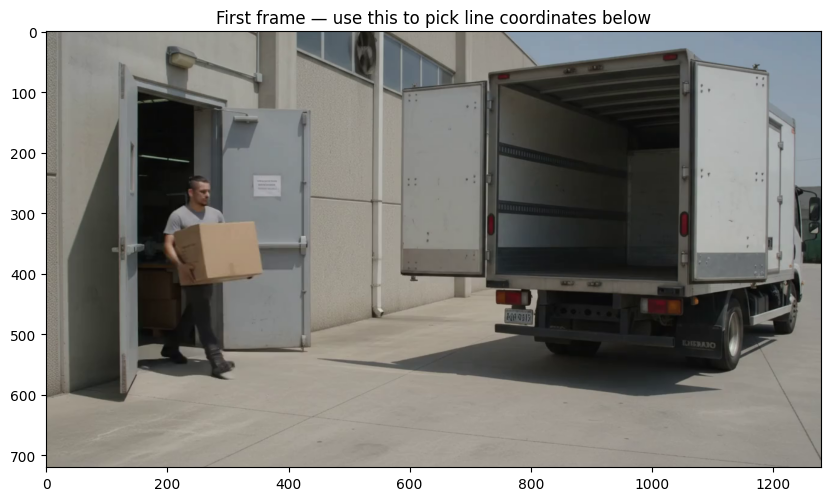

In [ ]:
# Step 3: Preview first frame to help you choose line coordinates
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

h, w = frame.shape[:2]
print(f'Video resolution: {w}x{h}')

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 8))
plt.imshow(frame_rgb)
plt.title('First frame — use this to pick line coordinates below')
plt.axis('on')  # keep axis so you can read pixel coordinates
plt.show()

## Step 4: Define the virtual counting line
Look at the frame above. Pick two points (x1,y1) and (x2,y2) that define a line
across the factory->truck path. The line should be roughly perpendicular to the
direction cartons travel.

Also define which side is "factory" and which is "truck" — this determines
counting direction.

Line: (600, 0) to (600, 720)
Factory side: left


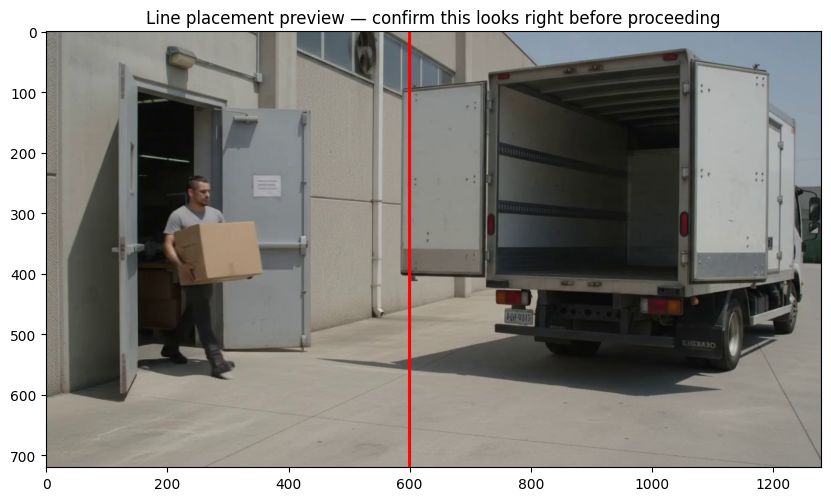

In [ ]:
# EDIT THESE COORDINATES based on the frame you saw above
LINE_START = (600, 0)        # vertical line, top of frame
LINE_END = (600, h)          # vertical line, bottom of frame

# Direction: which side of the line is the 'factory' side (before crossing)?
# 'left' means factory is left of the line, truck is right (cartons move left->right)
# 'right' means factory is right of the line, truck is left (cartons move right->left)
FACTORY_SIDE = 'left'   # factory door is on the left, truck is on the right

print(f'Line: {LINE_START} to {LINE_END}')
print(f'Factory side: {FACTORY_SIDE}')

# Visualize the line on the frame to confirm placement before running full video
frame_preview = frame.copy()
cv2.line(frame_preview, LINE_START, LINE_END, (0, 0, 255), 3)
frame_preview_rgb = cv2.cvtColor(frame_preview, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 8))
plt.imshow(frame_preview_rgb)
plt.title('Line placement preview — confirm this looks right before proceeding')
plt.show()

In [ ]:
# Step 5: Line-crossing counting logic

def get_side(point, line_start, line_end):
    """Returns which side of the line a point is on, using cross product sign.
    Positive = one side, negative = other side, ~0 = on the line."""
    x, y = point
    x1, y1 = line_start
    x2, y2 = line_end
    return (x2 - x1) * (y - y1) - (y2 - y1) * (x - x1)

def determine_factory_sign(factory_side, line_start, line_end, frame_h, frame_w):
    """Figures out whether the 'factory' side corresponds to positive or negative
    cross-product sign, based on the FACTORY_SIDE setting."""
    if factory_side == 'top':
        test_point = (frame_w // 2, 0)
    elif factory_side == 'bottom':
        test_point = (frame_w // 2, frame_h - 1)
    elif factory_side == 'left':
        test_point = (0, frame_h // 2)
    elif factory_side == 'right':
        test_point = (frame_w - 1, frame_h // 2)
    else:
        raise ValueError("FACTORY_SIDE must be 'top', 'bottom', 'left', or 'right'")
    sign = get_side(test_point, line_start, line_end)
    return 1 if sign > 0 else -1

FACTORY_SIGN = determine_factory_sign(FACTORY_SIDE, LINE_START, LINE_END, h, w)
print(f'Factory side sign: {FACTORY_SIGN}')

# Per-track state: last known side (factory=True/False), and whether already counted
track_state = {}   # track_id -> {'was_factory_side': bool, 'counted': bool}
counted_ids = set()

def check_crossing(track_id, centroid):
    """Call this every frame for every active track. Returns True if this call
    represents a NEW factory->truck crossing (should increment the count)."""
    sign = get_side(centroid, LINE_START, LINE_END)
    is_factory_side = (sign * FACTORY_SIGN) > 0

    if track_id not in track_state:
        track_state[track_id] = {'was_factory_side': is_factory_side, 'counted': False}
        return False

    state = track_state[track_id]
    crossed_factory_to_truck = state['was_factory_side'] and not is_factory_side

    state['was_factory_side'] = is_factory_side

    if crossed_factory_to_truck and track_id not in counted_ids:
        counted_ids.add(track_id)
        return True

    return False

print('Counting logic ready.')

Factory side sign: 1
Counting logic ready.


In [ ]:
# Step 6: Run detection+tracking+counting on the full video, save annotated output
from ultralytics import YOLO
import cv2

model = YOLO(model_path)

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
frame_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

output_path = 'counted_output.mp4'
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
writer = cv2.VideoWriter(output_path, fourcc, fps, (frame_w, frame_h))

total_count = 0
frame_num = 0

# Reset state for a fresh run
track_state.clear()
counted_ids.clear()

results_gen = model.track(source=video_path, tracker='bytetrack.yaml', conf=0.3, persist=True, stream=True)

for result in results_gen:
    frame = result.orig_img.copy()
    frame_num += 1

    if result.boxes is not None and result.boxes.id is not None:
        boxes = result.boxes.xyxy.cpu().numpy()
        track_ids = result.boxes.id.cpu().numpy().astype(int)

        for box, track_id in zip(boxes, track_ids):
            x1, y1, x2, y2 = box
            centroid = ((x1 + x2) / 2, (y1 + y2) / 2)

            newly_counted = check_crossing(track_id, centroid)
            if newly_counted:
                total_count += 1

            color = (0, 255, 0) if track_id in counted_ids else (255, 165, 0)
            cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
            cv2.putText(frame, f'ID:{track_id}', (int(x1), int(y1) - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    # Draw the counting line
    cv2.line(frame, LINE_START, LINE_END, (0, 0, 255), 3)
    # Draw running count overlay
    cv2.putText(frame, f'Count: {total_count}', (20, 50),
                cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)

    writer.write(frame)

cap.release()
writer.release()

print(f'Done. Total cartons counted: {total_count}')
print(f'Annotated output saved to: {output_path}')


video 1/1 (frame 1/1200) /content/looped_video.mp4: 384x640 2 box - v5 2024-10-30 7-43ams, 10.6ms
video 1/1 (frame 2/1200) /content/looped_video.mp4: 384x640 2 box - v5 2024-10-30 7-43ams, 10.6ms
video 1/1 (frame 3/1200) /content/looped_video.mp4: 384x640 2 box - v5 2024-10-30 7-43ams, 10.6ms
video 1/1 (frame 4/1200) /content/looped_video.mp4: 384x640 2 box - v5 2024-10-30 7-43ams, 10.7ms
video 1/1 (frame 5/1200) /content/looped_video.mp4: 384x640 2 box - v5 2024-10-30 7-43ams, 10.6ms
video 1/1 (frame 6/1200) /content/looped_video.mp4: 384x640 2 box - v5 2024-10-30 7-43ams, 10.6ms
video 1/1 (frame 7/1200) /content/looped_video.mp4: 384x640 1 box - v5 2024-10-30 7-43am, 10.6ms
video 1/1 (frame 8/1200) /content/looped_video.mp4: 384x640 2 box - v5 2024-10-30 7-43ams, 10.6ms
video 1/1 (frame 9/1200) /content/looped_video.mp4: 384x640 2 box - v5 2024-10-30 7-43ams, 10.6ms
video 1/1 (frame 10/1200) /content/looped_video.mp4: 384x640 1 box - v5 2024-10-30 7-43am, 10.6ms
video 1/1 (frame 11/

```markdown
# Line-Crossing Carton Counter (Module 2)

This repository/module implements an automated computer vision pipeline designed to count cardboard shipping cartons as they are loaded from a factory/warehouse into a delivery truck.

## 📌 Goal & Overview
The system uses a fine-tuned object detector (YOLOv8) paired with a multi-object tracker (ByteTrack) to track and count cartons uniquely and directionally as they cross a user-defined virtual line.

---

## ⚙️ Key Features & Constraints

* **Directional Counting**: Only tracks and counts cartons moving in the **Factory -> Truck** direction (e.g., Left-to-Right). Reverse movements (Truck -> Factory) are ignored.
* **No Double Counting**: Each carton is tracked using a unique `track_id` assigned by ByteTrack, ensuring it is counted only once even if it hovers or moves back and forth near the line.
* **Independent Multi-Object Tracking**: Multiple separate cartons carried by different laborers crossing the line simultaneously are counted independently.
* **Operational Assumption**: Cartons crossing the virtual line are not physically stacked (they are carried individually or side-by-side).

---

## 🛠️ Pipeline Workflow

### 1. Environment & Dependencies Setup
Install required libraries including Ultralytics (for YOLO) and headless OpenCV:
```bash
pip install ultralytics opencv-python-headless
```

### 2. Assets Upload
* Upload your custom fine-tuned YOLO model (`best.pt`).
* Upload a test video representing the loading area view.

### 3. Coordinate Definition (Virtual Line)
Using the first frame preview from the input video, determine the pixel coordinates for the virtual line and define the "factory" side where the movement originates:
```python
LINE_START = (600, 0)      # (x1, y1)
LINE_END = (600, 720)      # (x2, y2)
FACTORY_SIDE = 'left'      # 'left', 'right', 'top', or 'bottom'
```

### 4. Line-Crossing Algebraic Logic
The system uses the **vector cross-product** of the line segment and the tracked object's centroid to instantly classify which side of the line a carton is currently on:
$$\text{Side Sign} = (x_2 - x_1) * (y - y_1) - (y_2 - y_1) * (x - x_1)$$
- A state tracker (`track_state`) stores the historical side of each active ID.
- A crossing event is registered when the sign transitions from **Factory Side** to **Truck Side**.

### 5. Tracking & Count Execution
Streams inference on the video to minimize memory overhead:
- Uses standard `bytetrack.yaml` configuration with a confidence threshold of `0.3`.
- Automatically draws green bounding boxes for counted cartons, and orange for uncounted ones.
- Overlays a real-time counter and the virtual line on the processed video frames, saving the results to `counted_output.mp4`.

---

## 📊 Evaluation & Verification Checklist
When validating the output `counted_output.mp4`, verify:
1. Does the final printed count match your manual tally of cartons crossing the line?
2. Are cartons that remain on the factory side without crossing properly ignored?
3. Is reverse movement (e.g. walking a carton back inside) ignored?
4. Are multiple concurrent crossings correctly tracked and separately counted?
```

In [ ]:
!ffmpeg -i counted_output.mp4 -vcodec libx264 -y counted_output_h264.mp4 -loglevel quiet

from IPython.display import Video
Video('counted_output_h264.mp4', embed=True, width=500)

## What to check
1. Does the count match your manual count of cartons crossing the line in the video?
2. Does it correctly ignore cartons that don't cross the line (stay on factory side)?
3. Does it correctly ignore reverse movement (truck -> factory), if any exists in your video?
4. If multiple separate cartons cross at the same time (different laborers), are they
   each counted individually — not merged into one count?
5. Try a video with a few cartons deliberately walked back and forth near the line to
   stress-test the direction logic and no-double-count logic.

Report back the count vs your manual count, and any cases where it over/under-counted.

In [ ]:
import os
print("Current video_path:", video_path)
print("File exists:", os.path.exists(video_path))

# Run ffprobe with full output visible (not captured) to see the actual error
import subprocess
probe = subprocess.run(
    ['ffprobe', '-v', 'error', '-show_entries', 'format=duration',
     '-of', 'default=noprint_wrappers=1:nokey=1', video_path],
    capture_output=True, text=True
)
print("STDOUT:", repr(probe.stdout))
print("STDERR:", repr(probe.stderr))
print("Return code:", probe.returncode)

Current video_path: 6170600-uhd_2160_3840_25fps.mp4
File exists: False
STDOUT: ''
STDERR: '6170600-uhd_2160_3840_25fps.mp4: No such file or directory\n'
Return code: 1
